In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import seaborn as sns

from datasets import load_dataset
from pathlib import Path


In [2]:
dataset = "TimKoornstra/financial-tweets-sentiment"

print("---Loading Dataset---")
ds = load_dataset(dataset, split="train")
df = ds.to_pandas()

---Loading Dataset---


In [3]:
# Tải file raw ra data
ROOT = Path.cwd()

raw_output_dir = ROOT / ".." / "data" / "raw" / "text_b"
raw_output_dir.mkdir(parents=True, exist_ok=True)

raw_output_file = raw_output_dir / "financial_tweets_sentiment_raw.csv"
df.to_csv(raw_output_file)

In [4]:
print(df.info())
print("\nPhân bố nhãn:\n", df["sentiment"].value_counts())
print(df.head(5))

<class 'pandas.DataFrame'>
RangeIndex: 38091 entries, 0 to 38090
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   tweet      38091 non-null  str  
 1   sentiment  38091 non-null  int64
 2   url        38091 non-null  str  
dtypes: int64(1), str(2)
memory usage: 6.8 MB
None

Phân bố nhãn:
 sentiment
1    17368
0    12181
2     8542
Name: count, dtype: int64
                                               tweet  sentiment  \
0  $BYND - JPMorgan reels in expectations on Beyo...          2   
1  $CCL $RCL - Nomura points to bookings weakness...          2   
2  $CX - Cemex cut at Credit Suisse, J.P. Morgan ...          2   
3  $ESS: BTIG Research cuts to Neutral https://t....          2   
4  $FNKO - Funko slides after Piper Jaffray PT cu...          2   

                                                 url  
0  https://huggingface.co/datasets/zeroshot/twitt...  
1  https://huggingface.co/datasets/zeroshot/twitt...  
2  https:

In [5]:
# LABEL cho giá trị
# 0: Neutral (Trung tính)
# 1: Bullish (Tích cực / Kỳ vọng tăng)
# 2: Bearish (Tiêu cực / Kỳ vọng giảm)
label_map = {
    0: "Neutral",
    1: "Bullish",
    2: "Bearish"
}

df["label"] = df["sentiment"].map(label_map)

## 1. Text EDA

In [49]:
from IPython.display import display

def plot_text_eda(text: pd.Series, label: pd.Series):
    if len(text) != len(label):
        print(f"Invalid Length: {len(text)} != {len(label)}")
        return

    # 1. Tính 3 đại lượng (dùng str.count nhanh và nhẹ hơn str.findall)
    eda_df = pd.DataFrame({
        "label": label,
        "text_length": text.str.len(),                 # Độ dài văn bản (gồm khoảng trắng)
        "char_count": text.str.count(r"\S"),           # Số ký tự (không tính khoảng trắng)
        "word_count": text.str.split().str.len(),      # Số từ
    })

    label_order = ["Bullish", "Neutral", "Bearish"]
    palette = {
        "Bullish": "#2ecc71",  # Xanh lá - Tích cực
        "Neutral": "#3498db",  # Xanh dương - Trung tính
        "Bearish": "#e74c3c",  # Đỏ - Tiêu cực
    }

    metrics = [
        ("text_length", "Text Length"),
        ("char_count", "Character Count"),
        ("word_count", "Word Count"),
    ]

    # 2. TÍNH: Bảng thống kê theo từng nhãn lớp
    for col, title in metrics:
        stats = (
            eda_df.groupby("label")[col]
            .agg(
                count="count",
                mean="mean",
                std="std",
                min="min",
                q25=lambda s: s.quantile(0.25),
                median="median",
                q75=lambda s: s.quantile(0.75),
                max="max",
            )
            .reindex(label_order)
            .round(2)
        )
        print(f"\n=== Thống kê: {title} ===")
        display(stats)

    sns.set_theme(style="whitegrid", font_scale=1.05)
    fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 12))

    for row_idx, (col, title) in enumerate(metrics):
        ax_kde, ax_box = axes[row_idx, 0], axes[row_idx, 1]

        upper_limit = eda_df[col].quantile(0.995)
        sub_df = eda_df[eda_df[col] <= upper_limit]

        # Cột trái: Đường mật độ KDE
        sns.kdeplot(
            data=sub_df,
            x=col,
            hue="label",
            hue_order=label_order,
            palette=palette,
            common_norm=False,   # Chuẩn hóa riêng từng lớp vì số mẫu 3 lớp lệch nhau
            fill=True,
            alpha=0.15,
            linewidth=2,
            cut=0,               
            ax=ax_kde,
        )
        ax_kde.set_title(f"Density Distribution: {title}", fontweight="bold")
        ax_kde.set_xlabel(title)
        ax_kde.set_ylabel("Density")

        # Cột phải: Boxplot tách riêng 3 nhãn thành 3 dòng
        sns.boxplot(
            data=sub_df,
            x=col,
            y="label",
            order=label_order,
            hue="label",
            hue_order=label_order,
            palette=palette,
            legend=False,
            width=0.5,
            fliersize=2.5,
            ax=ax_box,
        )
        ax_box.set_title(f"Compare among labels: {title}", fontweight="bold")
        ax_box.set_xlabel(title)
        ax_box.set_ylabel("")

    sns.despine()
    plt.tight_layout()
    plt.show()
    
    return eda_df.drop(columns=['label'])


=== Thống kê: Text Length ===


,count,mean,std,min,q25,median,q75,max
label,,,,,,,,
Bullish,17368,93.88,71.93,3,52.0,83.0,131.0,3507
Neutral,12181,94.43,49.82,1,58.0,85.0,131.0,359
Bearish,8542,99.53,97.38,5,54.0,84.0,132.0,4229



=== Thống kê: Character Count ===


,count,mean,std,min,q25,median,q75,max
label,,,,,,,,
Bullish,17368,78.54,59.51,2,44.0,70.0,109.0,2864
Neutral,12181,81.04,42.27,0,50.0,73.0,114.0,316
Bearish,8542,83.38,80.63,4,45.0,71.0,110.0,3525



=== Thống kê: Word Count ===


,count,mean,std,min,q25,median,q75,max
label,,,,,,,,
Bullish,17368,15.42,12.45,1,8.0,13.0,20.0,636
Neutral,12181,13.83,7.83,0,9.0,12.0,18.0,63
Bearish,8542,16.49,16.75,1,9.0,13.0,21.0,701


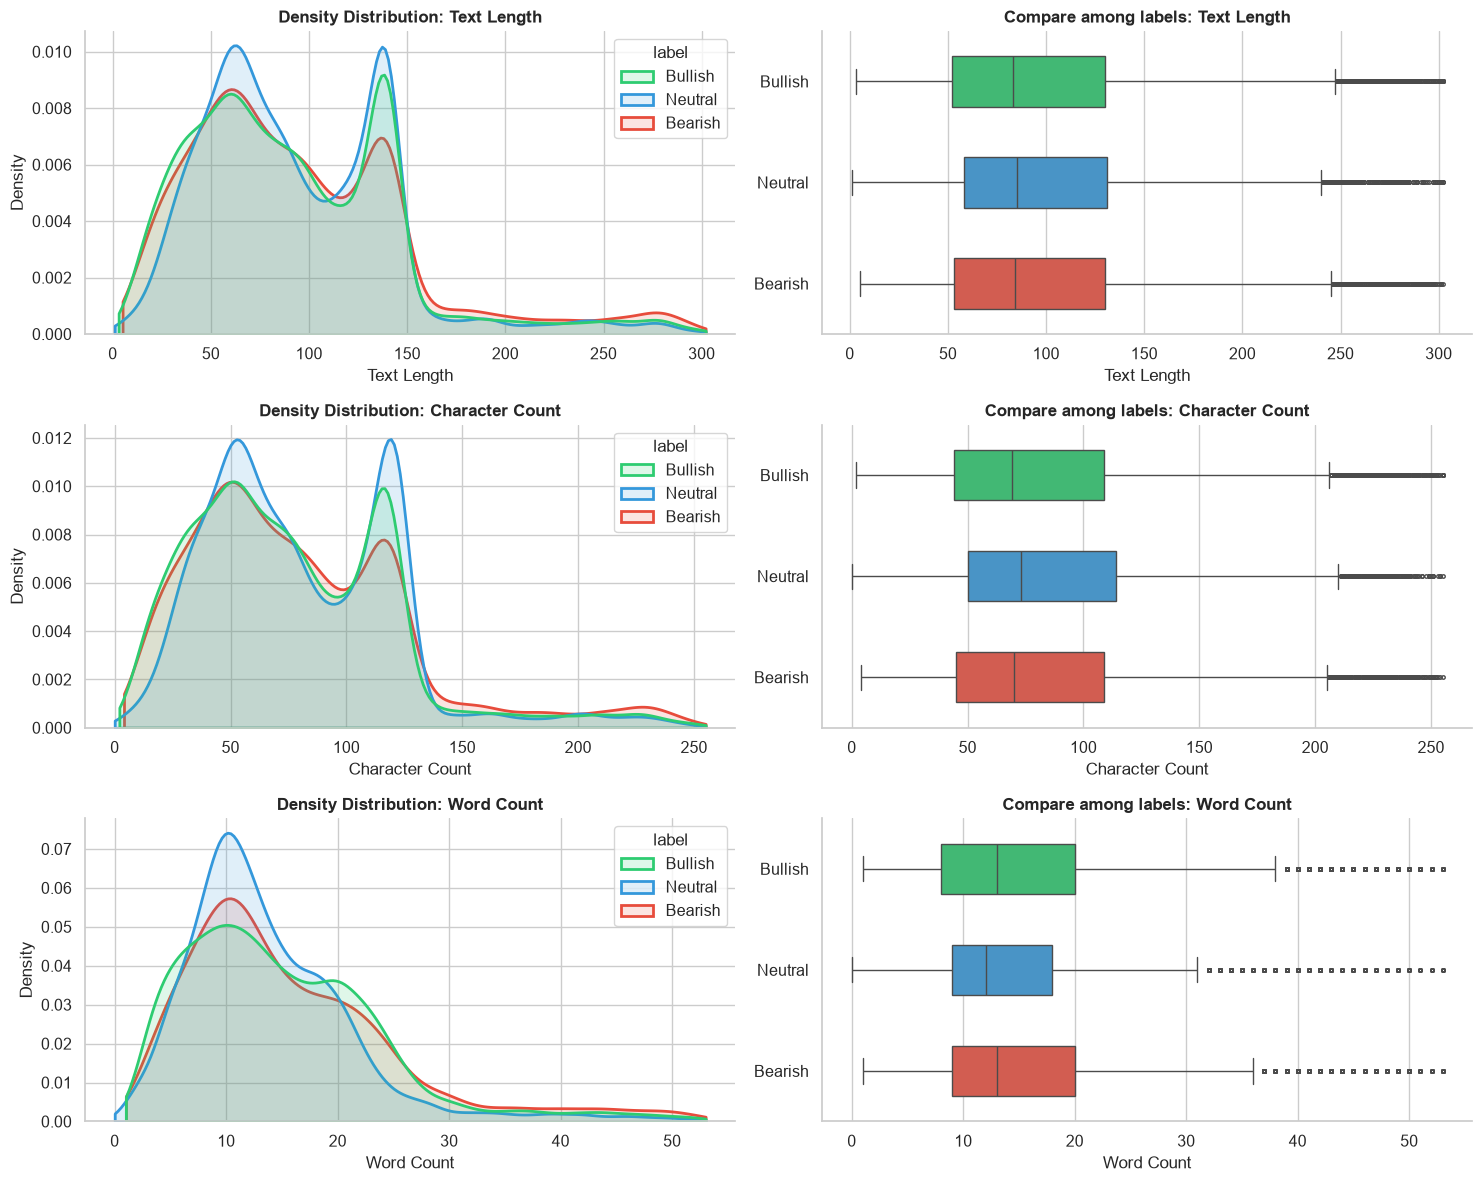

In [50]:
eda_df = plot_text_eda(df["tweet"], df['label'])
df = pd.concat([df, eda_df], axis=1)

### Đánh giá sơ tổng quan
- Có sự chênh lệch lớn giữa nhãn Neutral giữa Bullish và Bearish, max của Netrual thường rất nhỏ, trong khi Bullish và Bearish lại vô lớn hơn rất nhiều.

- Đáng chú ý, Neutral có các đoạn text outlier có min Character và min Word = 0, và Bearish, Bullish cũng có giá những giá trị min rất thấp, có thể không mang thông tin hữu ích về ngữ nghĩa

- Mật độ tập trung cao ở **vùng 50-140** sau đó thoái hóa dần về 300

- Nhìn Boxplot, ta thấy sự phân phối lệch phải, khi đường **Median** nằm lệch về phía bên trái hình hộp và mean > median ở mọi label
---

## Kiểm định Mann-Whitney U test
- Kiểm định thống kê **phi tham số (non-parametric)** dùng để **so sánh 2 nhóm độc lập**, nhằm kiểm tra xem 1 nhó có xu hướng mang giá trị lớn/nhỏ hơn nhóm kia 1 cách 1 hệ thống hay không.

- Giải quyết triệt để ngoại lại, vì loại bỏ giá trị độ dài tuyệt đối và chỉ dựa vào Rank

### 1. Cách hoạt động
- Ghép mọi câu lớp A và B lại rồi xếp từ ngắn đến dài theo **Rank**

- Đếm số số lần câu thuộc lớp A dài hơn câu lớp B

### 2. Kiểm định giả thuyết
- *$H_0$*: Hai lớp có phân phối độ dài như nhau (xác suất chọn ngẫu nhiên 1 câu lớp này dài hơn câu lớp kia = 50%)

- *$H_1$*: Tồn tại sự chênh lệch có hệ thống về độ dài giữa hai lớp

**Kết quả P-value (với mức ý nghĩa $\alpha = 0.05$):**
*   **P-value < 0.05 (Bác bỏ $H_0$):** Hai lớp có sự khác biệt có ý nghĩa thống kê
*   **P-value $\ge$ 0.05 (Chưa đủ cơ sở bác bỏ $H_0$):** 2 lớp không có sự khác biệt đáng kể

In [65]:
from scipy.stats import mannwhitneyu
from itertools import combinations

labels = df['label'].unique()
labels = labels[[1, 2, 0]]
# Tổ hợp chập 2 của các labels
label_combs = list(combinations(labels, 2))

alpha = 0.05

res = []

for target in ['text_length', 'char_count', 'word_count']:
    
    for(l1, l2) in label_combs:
        l1_length = df[df['label'] == l1][target]
        l2_length = df[df['label'] == l2][target]
        
        stat, p = mannwhitneyu(
            l1_length, l2_length,
            alternative='two-sided',
            method='auto'
            )
        
        p_bonferroni = min(p * len(label_combs), 1)
        
        r_rb = (2 * stat / (len(l1_length) * len(l2_length))) - 1
        
        res.append({
            'metric': target,
            'pair': f'{l1} vs {l2}',
            'u_stat': stat,
            'p_raw': p,
            'p_bonferroni': p_bonferroni,
            'reject_H0': p_bonferroni < alpha,
            'r_rb': round(r_rb, 4),
            'abs_r_rb': round(abs(r_rb), 4),
        })
    
res_df = pd.DataFrame(res)
display(res_df)

,metric,pair,u_stat,p_raw,p_bonferroni,reject_H0,r_rb,abs_r_rb
0,text_length,Bullish vs Neutral,101265634.0,3.953152e-10,1.185946e-09,True,-0.0427,0.0427
1,text_length,Bullish vs Bearish,72403888.5,1.710701e-03,5.132102e-03,True,-0.0239,0.0239
2,text_length,Neutral vs Bearish,52945320.0,2.989704e-02,8.969111e-02,False,0.0177,0.0177
3,char_count,Bullish vs Neutral,97857784.5,4.976692e-28,1.493008e-27,True,-0.0749,0.0749
4,char_count,Bullish vs Bearish,72263142.5,7.127486e-04,2.138246e-03,True,-0.0258,0.0258
5,char_count,Neutral vs Bearish,54393558.5,2.301996e-08,6.905989e-08,True,0.0455,0.0455
6,word_count,Bullish vs Neutral,113366727.5,6.889438e-26,2.066831e-25,True,0.0717,0.0717
7,word_count,Bullish vs Bearish,72052229.0,1.698714e-04,5.096142e-04,True,-0.0287,0.0287
8,word_count,Neutral vs Bearish,46908897.5,1.305528e-33,3.916585e-33,True,-0.0983,0.0983


In [62]:
print(res)
print(labels)

[(np.float64(75953567.5), np.float64(0.005132102222558102), np.float64(0.023926529179632228)), (np.float64(51104782.0), np.float64(0.089691114367311), np.float64(0.017688959113178027)), (np.float64(101265634.0), np.float64(1.1859455757034026e-09), np.float64(0.04267515942835365))]
<ArrowStringArray>
['Bearish', 'Bullish', 'Neutral']
Length: 3, dtype: str
